<img src="https://raw.githubusercontent.com/doctolib-lab/doctosae/main/.github/assets/doctosae_colab_banner.png" width="100%">

<p align="center">
<a href="https://arxiv.org/abs/2611.18179"><img src="https://img.shields.io/badge/arXiv-2611.18179-b31b1b.svg?logo=arxiv&logoColor=white"></a>
<a href="https://pypi.org/project/doctosae/"><img src="https://img.shields.io/pypi/v/doctosae?color=107ACA"></a>
<a href="https://pepy.tech/projects/doctosae"><img src="https://static.pepy.tech/badge/doctosae"></a>
<a href="https://huggingface.co/collections/doctolib-lab/doctosae"><img src="https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-checkpoints-yellow"></a>
<a href="https://github.com/doctolib-lab/doctosae"><img src="https://img.shields.io/badge/GitHub-doctolib--lab%2Fdoctosae-0B1F42?logo=github"></a>
<a href="https://colab.research.google.com/github/doctolib-lab/doctosae/blob/main/package/examples/doctosae_colab.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg"></a>
</p>

# DoctoSAE in 10 minutes

Dense retrievers are accurate but opaque: nobody can say **why** a passage ranked first. DoctoSAE trains a TopK
**sparse autoencoder** on the frozen embeddings of a text encoder, so that every query and document becomes a code
with at most *k* active features. Documents are ranked by cosine similarity of these codes, and every feature can
be **described** from the texts that fire it.

<img src="https://raw.githubusercontent.com/doctolib-lab/doctosae/main/.github/assets/doctosae_overview.png" width="100%">

| Step | What you do | What you get |
| :---: | --- | --- |
| **0** | Install | `pip install doctosae` |
| **1** | Load a medical benchmark | NFCorpus, 3,633 nutrition and medicine abstracts |
| **2** | Load a pretrained DoctoSAE | the paper checkpoint `k256_m3072` and its frozen BGE encoder |
| **3** | Look inside a sparse code | 3,072 features, 256 active per text |
| **4** | Evaluate retrieval | NDCG@10 out of domain, next to Table 1 of the paper |
| **5** | Interpret the features | one card per feature: top texts and TF IDF terms |
| **6** | Explain one retrieval | the features that make one passage outrank another |
| **7** | Search with your own question | ranked abstracts and the features behind them |
| **8** | Train your own DoctoSAE | the paper objective, in about a minute on a GPU |

> 💡 **Before you start:** *Runtime → Change runtime type → T4 GPU*. Everything also runs on CPU, but embedding
> the corpus then takes about 15 minutes instead of 1.

> ⚠️ **Research tool:** feature descriptions and rankings can be wrong. Never use them for diagnosis, treatment
> or any other clinical decision.

## 0 ⚙️ Setup

Install the package, then run the helper cell: it holds the charts and the HTML of this notebook, so that every
step below shows only the DoctoSAE calls. There is no need to read it.

In [ ]:
%pip install -q "doctosae>=0.1.1"

In [ ]:
# @title 🎨 Notebook helpers: charts and cards (run it, no need to read)
import html
import logging
import textwrap
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

%config InlineBackend.figure_format = "retina"
warnings.filterwarnings("ignore")
logging.getLogger("doctosae").setLevel(logging.WARNING)

NAVY, BLUE, ICE, OFFWHITE, GOLD, MUTED, DARK = (
    "#0B1F42", "#107ACA", "#E8F4FD", "#F5F7FA", "#D97706", "#4A5568", "#1A1A2E",
)  # fmt: skip
plt.rcParams.update(
    {
        "figure.dpi": 100, "figure.facecolor": "white", "axes.facecolor": "white",
        "axes.edgecolor": "#CBD5E0", "axes.labelcolor": DARK, "axes.labelsize": 12,
        "axes.titlecolor": NAVY, "axes.titleweight": "bold", "axes.titlesize": 15, "axes.titlepad": 14,
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
        "grid.color": "#EDF2F7", "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
        "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.frameon": False, "legend.fontsize": 11,
    }
)  # fmt: skip
CSS = f"""<style>
.ds {{font-family: -apple-system, 'Segoe UI', Roboto, sans-serif; color: {DARK}; font-size: 14px;
      line-height: 1.5; max-width: 1100px}}
.ds .card {{border: 1px solid #D6E4F0; border-top: 5px solid {BLUE}; border-radius: 10px; padding: 12px 16px;
            margin: 8px 0; background: white}}
.ds .meta {{color: {MUTED}; font-size: 12px; letter-spacing: .5px; text-transform: uppercase}}
.ds .title {{color: {NAVY}; font-weight: 700; font-size: 16px; margin: 2px 0 6px 0}}
.ds .chip {{display: inline-block; background: {ICE}; color: {NAVY}; border-radius: 12px;
            padding: 1px 10px; margin: 2px 3px 2px 0; font-size: 12px}}
.ds .chip.q {{background: {OFFWHITE}; color: {DARK}}}
.ds details {{margin: 4px 0}} .ds summary {{cursor: pointer}}
.ds .score {{color: {BLUE}; font-weight: 700}}
.ds .grid {{display: grid; grid-template-columns: repeat(auto-fill, minmax(330px, 1fr)); gap: 0 14px}}
</style>"""


def _html(body):
    display(HTML(CSS + f'<div class="ds">{body}</div>'))


def _chips(texts, kind=""):
    return "".join(f'<span class="chip {kind}">{html.escape(str(t))}</span>' for t in texts)


def _abstract(text, title=None, score=None, open_=False, extra=""):
    """A collapsible abstract: the title (or the first words) as summary, the full text inside."""
    title = title or text[:120] + "..."
    head = f'<span class="score">{score:.3f}</span> ' if score is not None else ""
    flag = " open" if open_ else ""
    body = html.escape(text)
    return f"<details{flag}><summary>{head}<b>{html.escape(title)}</b></summary>{body}{extra}</details>"


_NAMES = {}


def feature_name(interpreter, feature, cards=()):
    """LLM topic when a card has one, else the two strongest TF IDF terms of the feature."""
    for card in cards:
        if card.feature == feature and card.has_label:
            return card.topic
    if feature not in _NAMES:
        terms = interpreter.describe([int(feature)])[0].tfidf_terms
        _NAMES[feature] = " · ".join(terms[:2]) or f"feature {feature}"
    return _NAMES[feature]


def show_documents(corpus):
    items = "".join(
        f'<div class="card"><div class="meta">{row.doc_id}</div>'
        f'<div class="title">{html.escape(row.title)}</div>{html.escape(row.body)}</div>'
        for row in corpus.itertuples()
    )
    _html(items)


def plot_code(dense, code_row, title=""):
    sparse = code_row.toarray().ravel()
    active = np.flatnonzero(sparse)
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), gridspec_kw={"hspace": 0.7})
    axes[0].bar(np.arange(dense.size), dense, color=MUTED, width=1.0)
    axes[0].set_title(f"Dense embedding: all {dense.size:,} dimensions are non zero", loc="left")
    axes[1].vlines(active, 0, sparse[active], color=BLUE, linewidth=1.2)
    axes[1].scatter(active, sparse[active], color=BLUE, s=8, zorder=3)
    axes[1].set_title(f"DoctoSAE code: {active.size} of {sparse.size:,} features fire", loc="left")
    axes[1].set_xlabel("feature")
    for ax, n in zip(axes, (dense.size, sparse.size), strict=True):
        ax.set_xlim(0, n)
        ax.set_yticks([])
        ax.grid(False)
    fig.suptitle(textwrap.shorten(title, 95), x=0.125, ha="left", y=1.0, color=MUTED, fontsize=12)
    plt.show()


def plot_firing(codes):
    fires_on = np.asarray((codes > 0).sum(axis=0)).ravel()
    n_docs = codes.shape[0]
    edges = np.unique(np.round(np.logspace(0, np.log10(n_docs) + 0.01, 45))) - 0.5
    fig, ax = plt.subplots(figsize=(11, 3.8))
    _, bins, patches = ax.hist(fires_on[fires_on > 0], bins=edges, color=BLUE, edgecolor="white")
    for patch, left in zip(patches, bins[:-1], strict=True):
        if left > 0.05 * n_docs:
            patch.set_facecolor(MUTED)
    ax.set_xscale("log")
    ax.set_xlabel("number of NFCorpus abstracts the feature fires on")
    ax.set_ylabel("features")
    ax.set_title(f"{(fires_on > 0).sum():,} of {fires_on.size:,} features fire on NFCorpus", loc="left")
    ax.text(0.99, 0.92, "blue: topic specific\ngrey: generic (over 5% of abstracts)", transform=ax.transAxes,
            ha="right", va="top", color=MUTED, fontsize=11)  # fmt: skip
    plt.show()


def show_scores(scores):
    table = pd.DataFrame(scores).T.drop(columns="n_queries")
    styled = table.style.format("{:.3f}").background_gradient(cmap="Blues", axis=0)
    display(styled.set_properties(**{"font-size": "14px"}))


def plot_paper_table(this_notebook):
    paper = pd.DataFrame(
        {
            "original embeddings": [53.06, 38.17, 77.24, 27.04, 12.72, 27.78],
            "k = 64": [57.07, 31.89, 68.75, 22.50, 8.30, 22.72],
            "k = 256": [60.50, 35.61, 73.85, 28.10, 10.06, 29.05],
            "dense SAE (k = 1024)": [61.87, 36.62, 75.05, 27.21, 8.37, 27.33],
        },
        index=["CURE\n(in domain)", "NFCorpus", "MIRIAD", "R2MED\nBioinformatics", "R2MED\nBiology",
               "R2MED Medical\nSciences"],
    )  # fmt: skip
    ax = paper.plot.bar(figsize=(11, 4.8), color=[MUTED, "#A8C4E0", BLUE, NAVY], width=0.8, rot=0)
    ax.scatter([1.1], [100 * this_notebook], marker="*", s=380, color=GOLD, edgecolor="white", zorder=5,
               label=f"this notebook: {100 * this_notebook:.2f}")  # fmt: skip
    ax.set_ylabel("NDCG@10 (%)")
    ax.set_title("Trained on CURE only, the sparse codes transfer to five unseen corpora", loc="left")
    ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
    plt.show()


def show_cards(cards):
    items = []
    for card in cards:
        title = card.topic if card.has_label else " · ".join(card.tfidf_terms[:3])
        about = f"<p>{html.escape(card.description)}</p>" if card.has_label and card.description else ""
        docs = "".join(
            _abstract(d["text"], title=d.get("title") or None, score=d["activation"])
            for d in card.top_documents[:3]
        )
        items.append(
            f'<div class="card"><div class="meta">feature {card.feature} · {card.n_documents} abstracts '
            f'({100 * card.firing_rate:.1f}%) · {card.n_queries} queries</div><div class="title">'
            f"{html.escape(title)}</div>{about}{_chips(card.tfidf_terms[:6])}"
            f'<div class="meta" style="margin-top:10px">abstracts that fire it most</div>{docs}'
            f'<div class="meta" style="margin-top:8px">queries</div>'
            f"{_chips([q['text'] for q in card.top_queries[:4]], 'q')}</div>"
        )
    _html(f'<div class="grid">{"".join(items)}</div>')


def show_explanation(explanation, interpreter):
    e = explanation
    names = [
        n or feature_name(interpreter, f) for f, n in zip(e.features, e.names or [None] * 99, strict=False)
    ]
    labels = [textwrap.shorten(f"{n}  (#{f})", 42) for f, n in zip(e.features, names, strict=True)]
    y = np.arange(len(labels))[::-1]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(labels) + 1.6))
    ax.barh(y + 0.2, e.contribution_a, height=0.38, color=BLUE, label=f"A, rank {e.rank_a}")
    ax.barh(y - 0.2, e.contribution_b, height=0.38, color=GOLD, label=f"B, rank {e.rank_b}")
    ax.set_yticks(y, labels)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("contribution to the cosine of the query and the passage")
    ax.set_title("\n".join(textwrap.wrap(f"Why A outranks B for “{e.query}”", 70)), loc="left")
    ax.legend(loc="lower right")
    plt.show()
    _html(
        f'<div class="card"><div class="meta">query</div><div class="title">{html.escape(e.query)}</div>'
        f'<div class="meta" style="color:{BLUE}">A · rank {e.rank_a} · cosine {e.cosine_a:.3f}</div>'
        f"{_abstract(e.passage_a, open_=True)}"
        f'<div class="meta" style="color:{GOLD};margin-top:8px">B · rank {e.rank_b} · cosine {e.cosine_b:.3f}'
        f"</div>{_abstract(e.passage_b, open_=True)}</div>"
    )


def search_engine(sae, embedder, data, interpreter, corpus_codes, cards=()):
    """``ask(question)`` ranks every abstract and shows the topic specific features behind each result."""
    from doctosae import search
    from doctosae.retrieval import encode_corpus

    corpus = data.dataset.corpus
    firing = np.asarray((corpus_codes > 0).sum(axis=0)).ravel() / corpus_codes.shape[0]

    def ask(question, top_k=5):
        q_emb = embedder.encode_queries([question])
        q_code = encode_corpus(sae, q_emb)
        ranked = q_code.indices[np.argsort(-q_code.data)]
        specific = [f for f in ranked if 0 < firing[f] < 0.05][:6]
        idx, sc = search(sae, q_emb, data.corpus, top_k=top_k)
        rows = []
        for rank, (i, s) in enumerate(zip(idx[0], sc[0], strict=True), start=1):
            row = corpus_codes[i].toarray().ravel()
            shared = [feature_name(interpreter, f, cards) for f in specific if row[f] > 0]
            chips = f'<div style="margin-top:6px">{_chips(shared)}</div>' if shared else ""
            abstract = _abstract(corpus.body.iloc[i], corpus.title.iloc[i], s, rank == 1, chips)
            rows.append(f"<div>{rank}. {abstract}</div>")
        names = [feature_name(interpreter, f, cards) for f in specific]
        _html(
            f'<div class="card"><div class="meta">your question</div><div class="title">🔍 '
            f'{html.escape(question)}</div><div class="meta">its strongest topic specific features</div>'
            f'{_chips(names)}<div class="meta" style="margin-top:10px">top {top_k} abstracts</div>'
            f"{''.join(rows)}</div>"
        )

    return ask


def plot_training(history, dense):
    history = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(
        history["step"], history["val_ndcg@10"], color=BLUE, marker="o", lw=2, label="your DoctoSAE, k = 64"
    )
    ax.axhline(dense, color=MUTED, linestyle="--", lw=1.5, label="dense embeddings")
    ax.set_xlabel("training step")
    ax.set_ylabel("validation NDCG@10")
    ax.set_title("Training on NFCorpus", loc="left")
    ax.legend(loc="lower right")
    plt.show()

In [ ]:
import torch

from doctosae import (
    DoctoSAE,
    Embedder,
    Interpreter,
    Trainer,
    TrainingConfig,
    evaluate,
    load_dataset,
    load_pretrained,
    search,
)
from doctosae.retrieval import encode_corpus

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
device

'mps'

## 1 💾 Load a medical benchmark

Six benchmarks are registered: `cure` (the training set of the paper), `nfcorpus`, `miriad` and three R2MED
subsets. They download from the Hugging Face Hub at pinned revisions, with the splits of the paper.

In [ ]:
dataset = load_dataset("nfcorpus")
show_documents(dataset.corpus.head(3))

## 2 🤗 Load a pretrained DoctoSAE and its encoder

The checkpoints of the paper are in the
[DoctoSAE collection](https://huggingface.co/collections/doctolib-lab/doctosae). Each one records its encoder
and query instruction, so `Embedder.from_sae` rebuilds the exact encoder it was trained on.

> 🔁 **Transfer:** this checkpoint was trained on **CURE** only. NFCorpus is **out of domain**: everything below
> shows how sparse codes and their explanations transfer to a corpus the SAE never saw.

In [ ]:
sae = load_pretrained("bge", k=256)  # doctolib-lab/doctosae-bge-large-en-v1.5/k256_m3072
embedder = Embedder.from_sae(sae, device=device)  # BAAI/bge-large-en-v1.5, frozen
data = embedder.embed_dataset(dataset)  # every document and query, about 1 minute on a T4

## 3 🔎 Look inside a sparse code

A dense embedding spreads its meaning over all 1,024 dimensions. Its DoctoSAE code has 3,072 features, and
exactly k = 256 of them fire: each one is a concept that can be described.

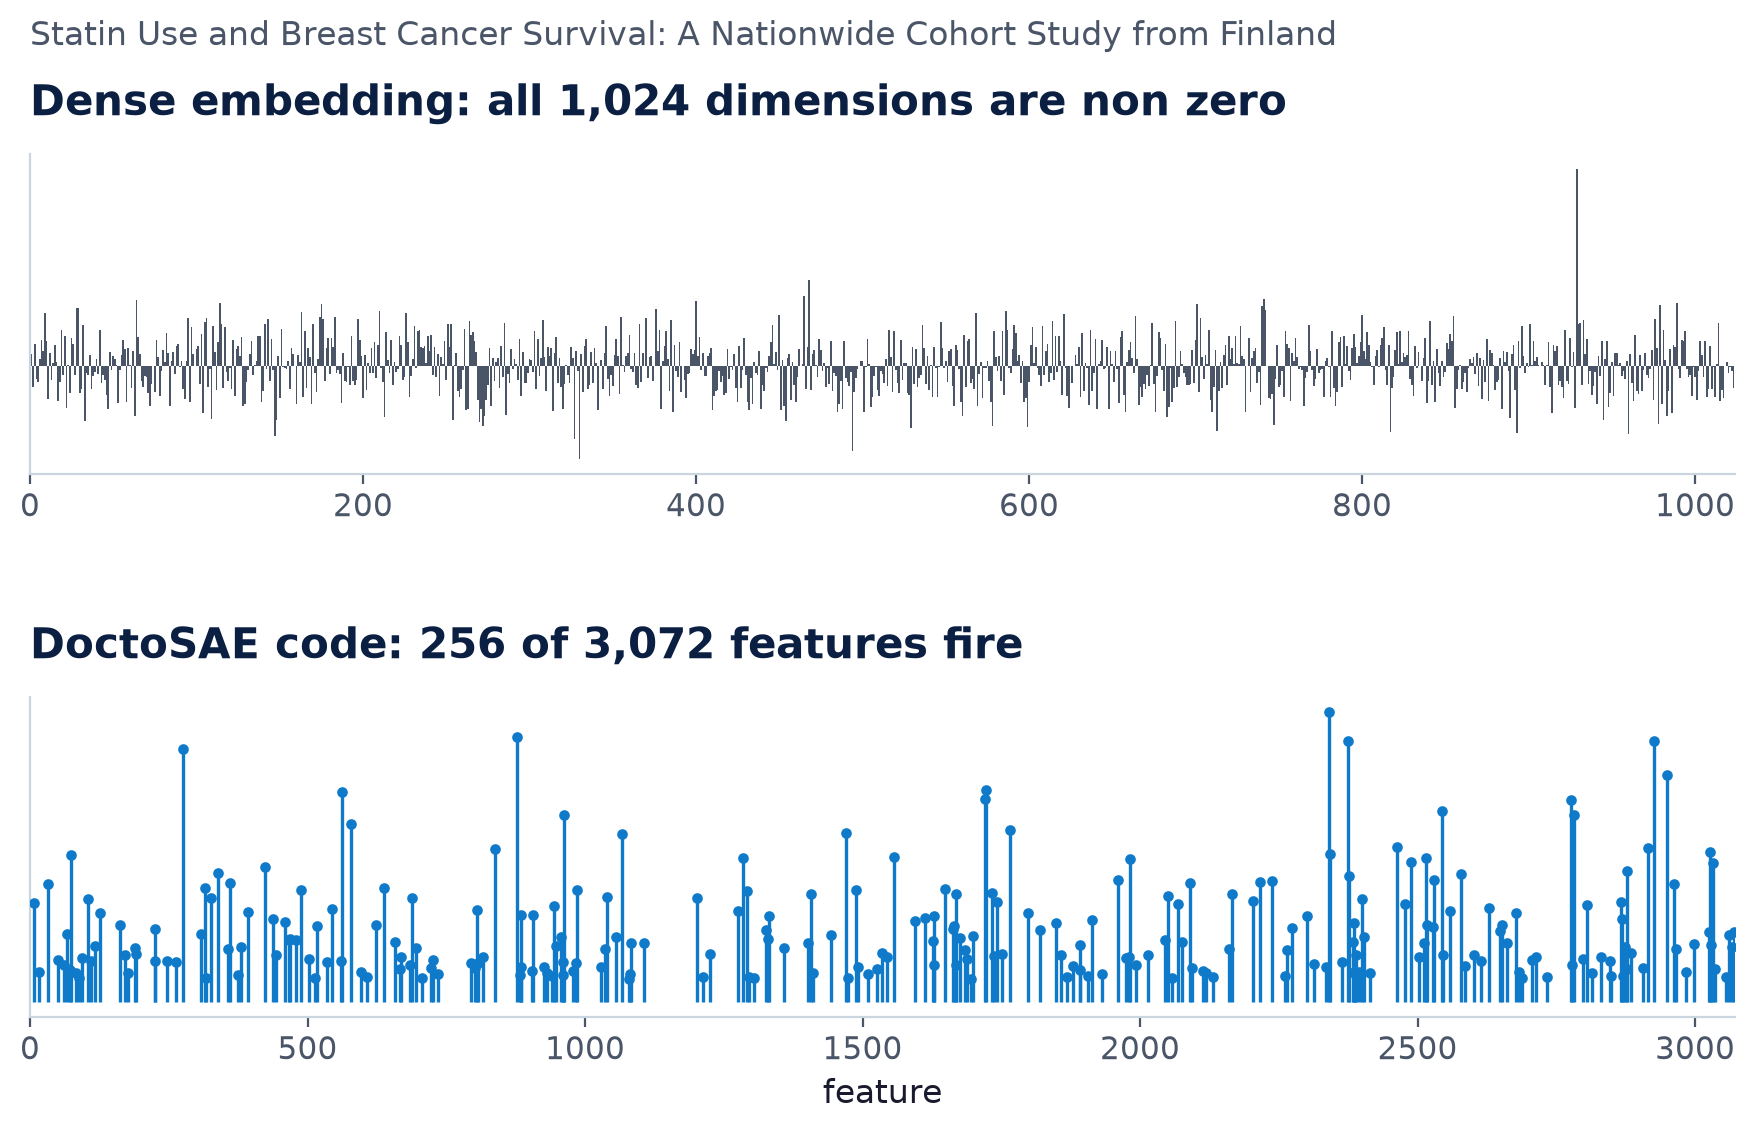

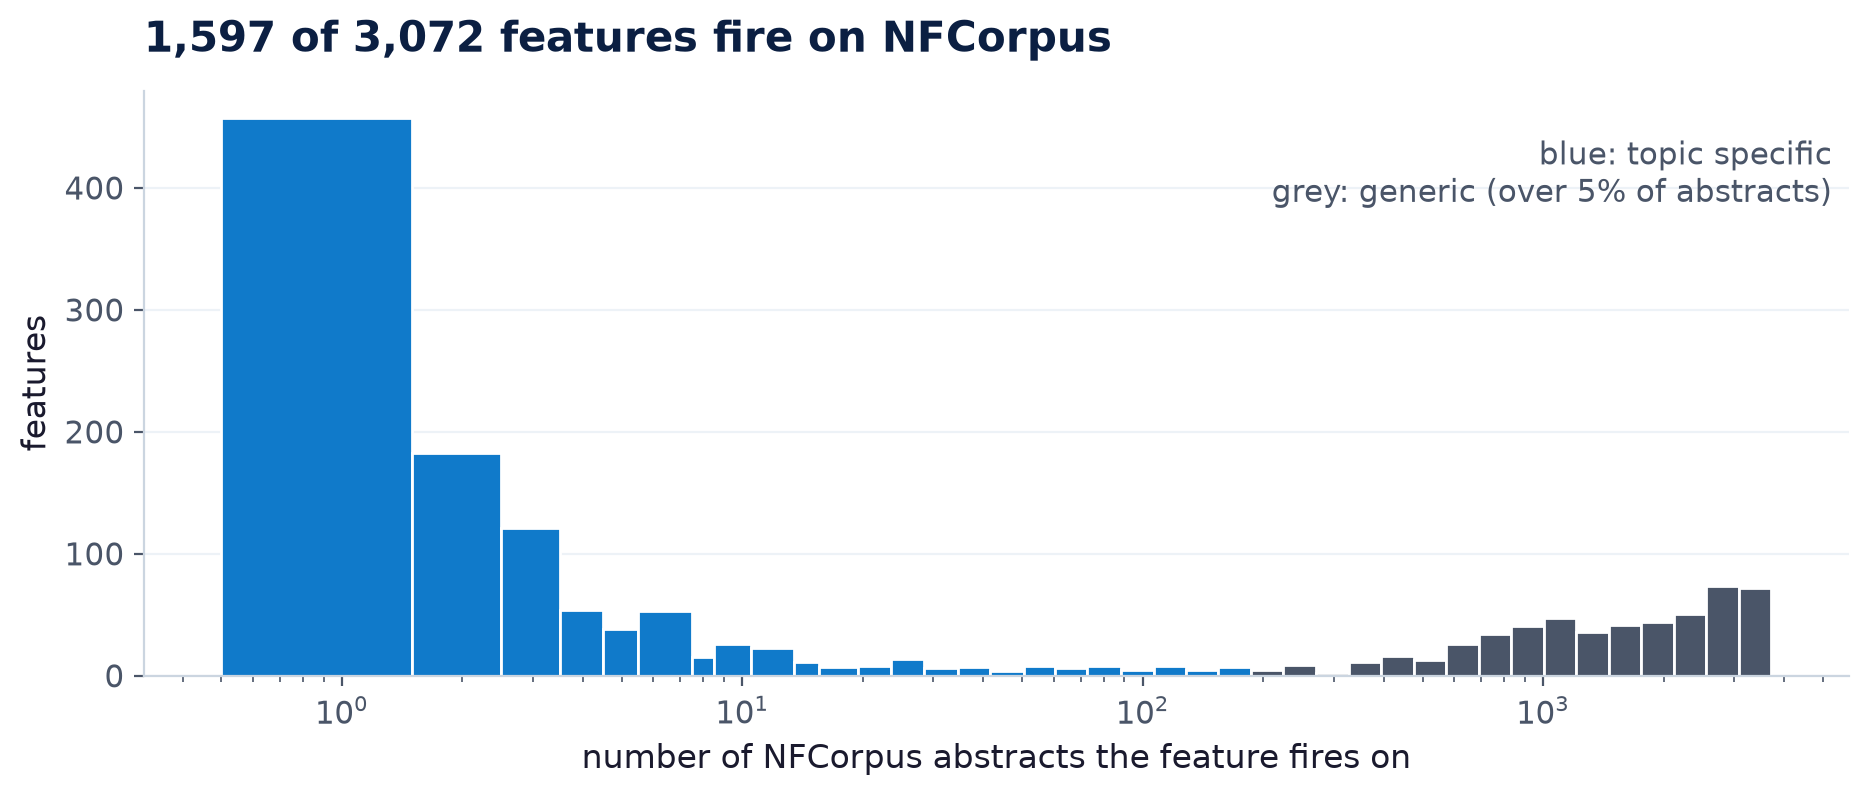

In [ ]:
corpus_codes = encode_corpus(sae, data.corpus, device=device)  # sparse matrix, one row per document
plot_code(data.corpus[0], corpus_codes[0], title=dataset.corpus.title.iloc[0])
plot_firing(corpus_codes)

## 4 🎯 Evaluate retrieval

Every test query ranks the whole corpus by cosine similarity, and NDCG@10 is computed exactly as in the paper.
`None` in place of an SAE scores the original dense embeddings.

,ndcg@10,recall@100,mrr@10
dense BGE embeddings,0.382,0.364,0.574
"DoctoSAE, k = 256, trained on CURE",0.356,0.338,0.546


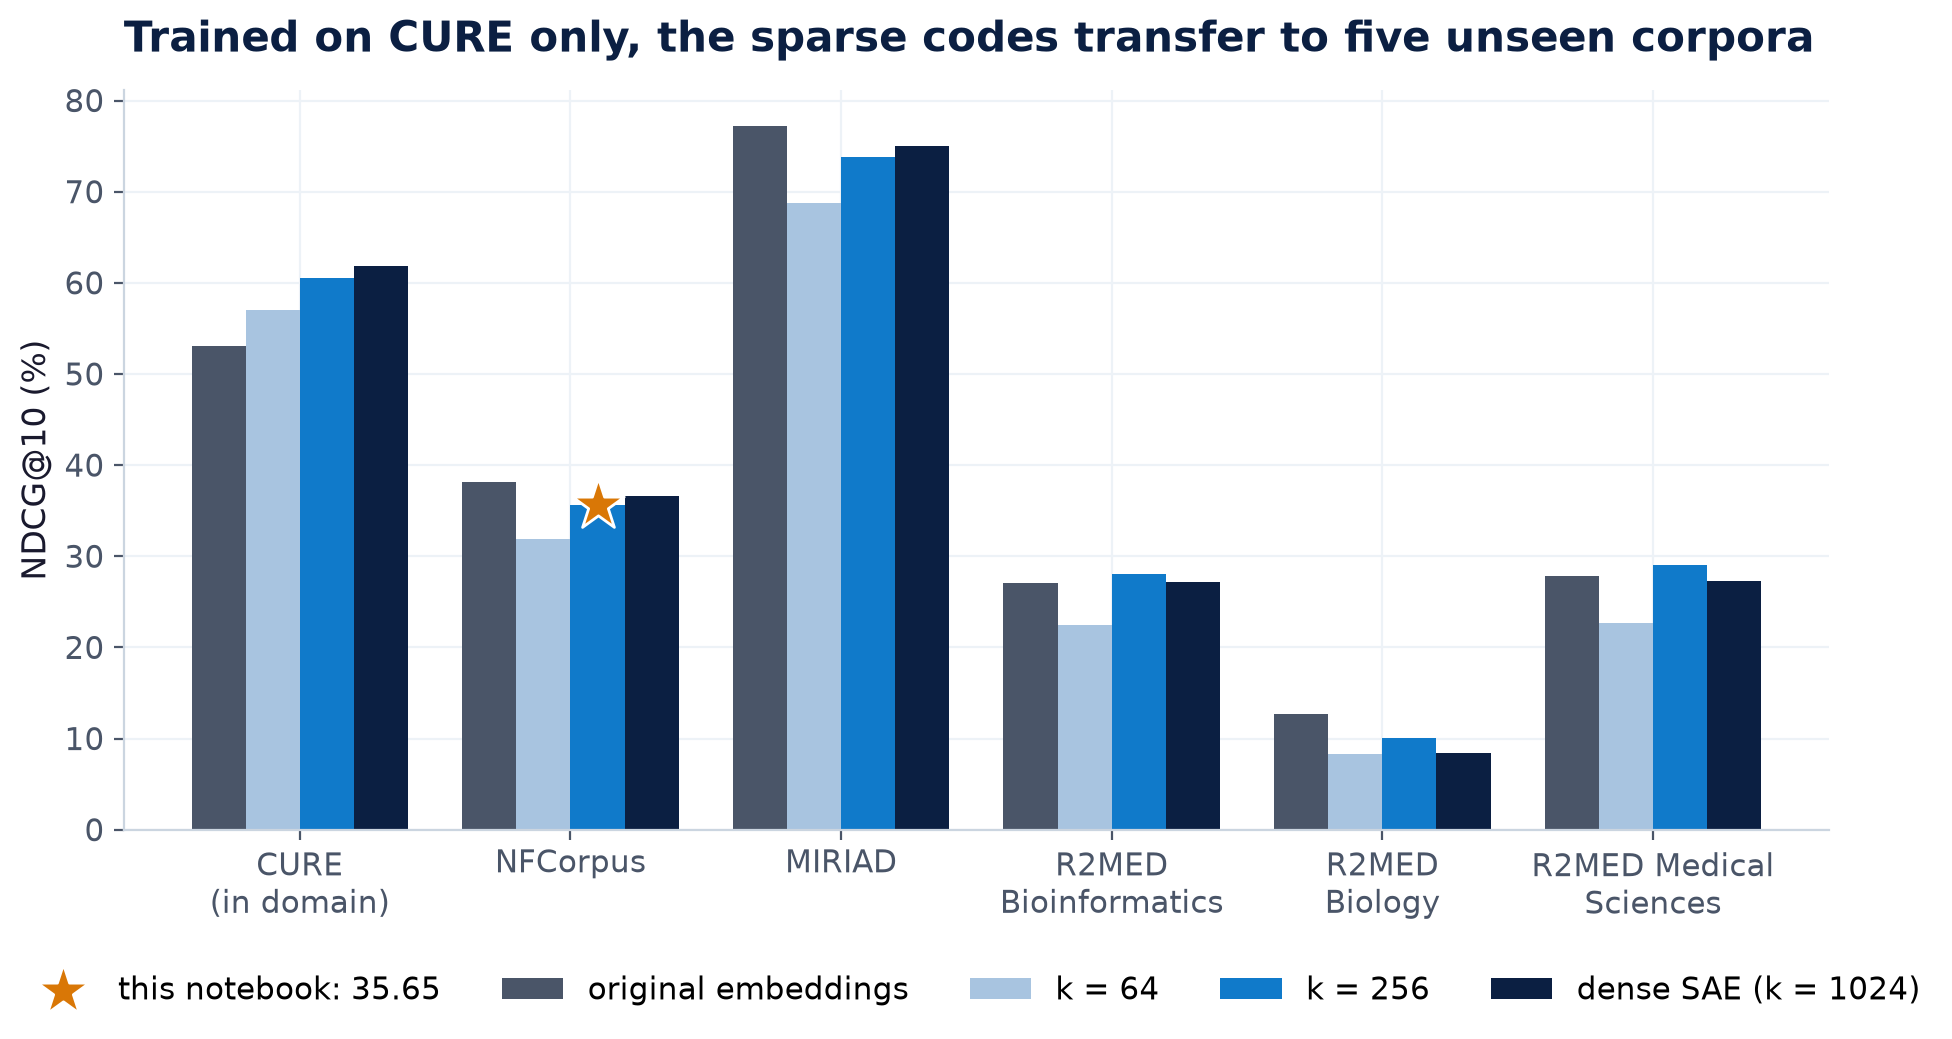

In [ ]:
scores = {
    "dense BGE embeddings": evaluate(None, data, split="test"),
    "DoctoSAE, k = 256, trained on CURE": evaluate(sae, data, split="test"),
}
show_scores(scores)
plot_paper_table(this_notebook=scores["DoctoSAE, k = 256, trained on CURE"]["ndcg@10"])

In domain (CURE), every sparse model **beats** the original embeddings. Out of domain, the sparse codes keep most
of the dense quality, and on the R2MED corpora, the farthest from CURE, k = 256 matches or beats the dense SAE.
The gold star is the number this notebook just measured.

## 5 🧠 Interpret the features

The `Interpreter` selects features that fire on enough documents and queries, and writes one card per feature:
the texts that fire it most, TF IDF terms and, with an LLM, a written topic. Click a title to read the abstract.

In [ ]:
interpreter = Interpreter(sae, data, split="train")
features = interpreter.select_features(n=6, min_documents=10, min_queries=10, firing_rate_band=(0.005, 0.05))
cards = interpreter.describe(features)
show_cards(cards)

### Optional: written topics with MedGemma

`google/medgemma-4b-it` is the Interpreter LLM of the paper. Accept its terms on the Hugging Face Hub, add a
token with `huggingface_hub.login()`, tick the box and run the cell: about 30 seconds per feature on a T4. Any
OpenAI compatible server works too, through `doctosae.OpenAICompatibleLLM`.

In [ ]:
# @title Label the features with MedGemma
use_medgemma = False  # @param {type:"boolean"}

if use_medgemma:
    from doctosae import TransformersLLM

    cards = interpreter.describe(features, llm=TransformersLLM("google/medgemma-4b-it"))
    show_cards(cards)

## 6 💡 Explain one retrieval

The cosine of two codes is a sum of one contribution per feature (Figure 2 of the paper). `explain` keeps the
features whose contributions differ most between two passages: here the first and the tenth result of a query.

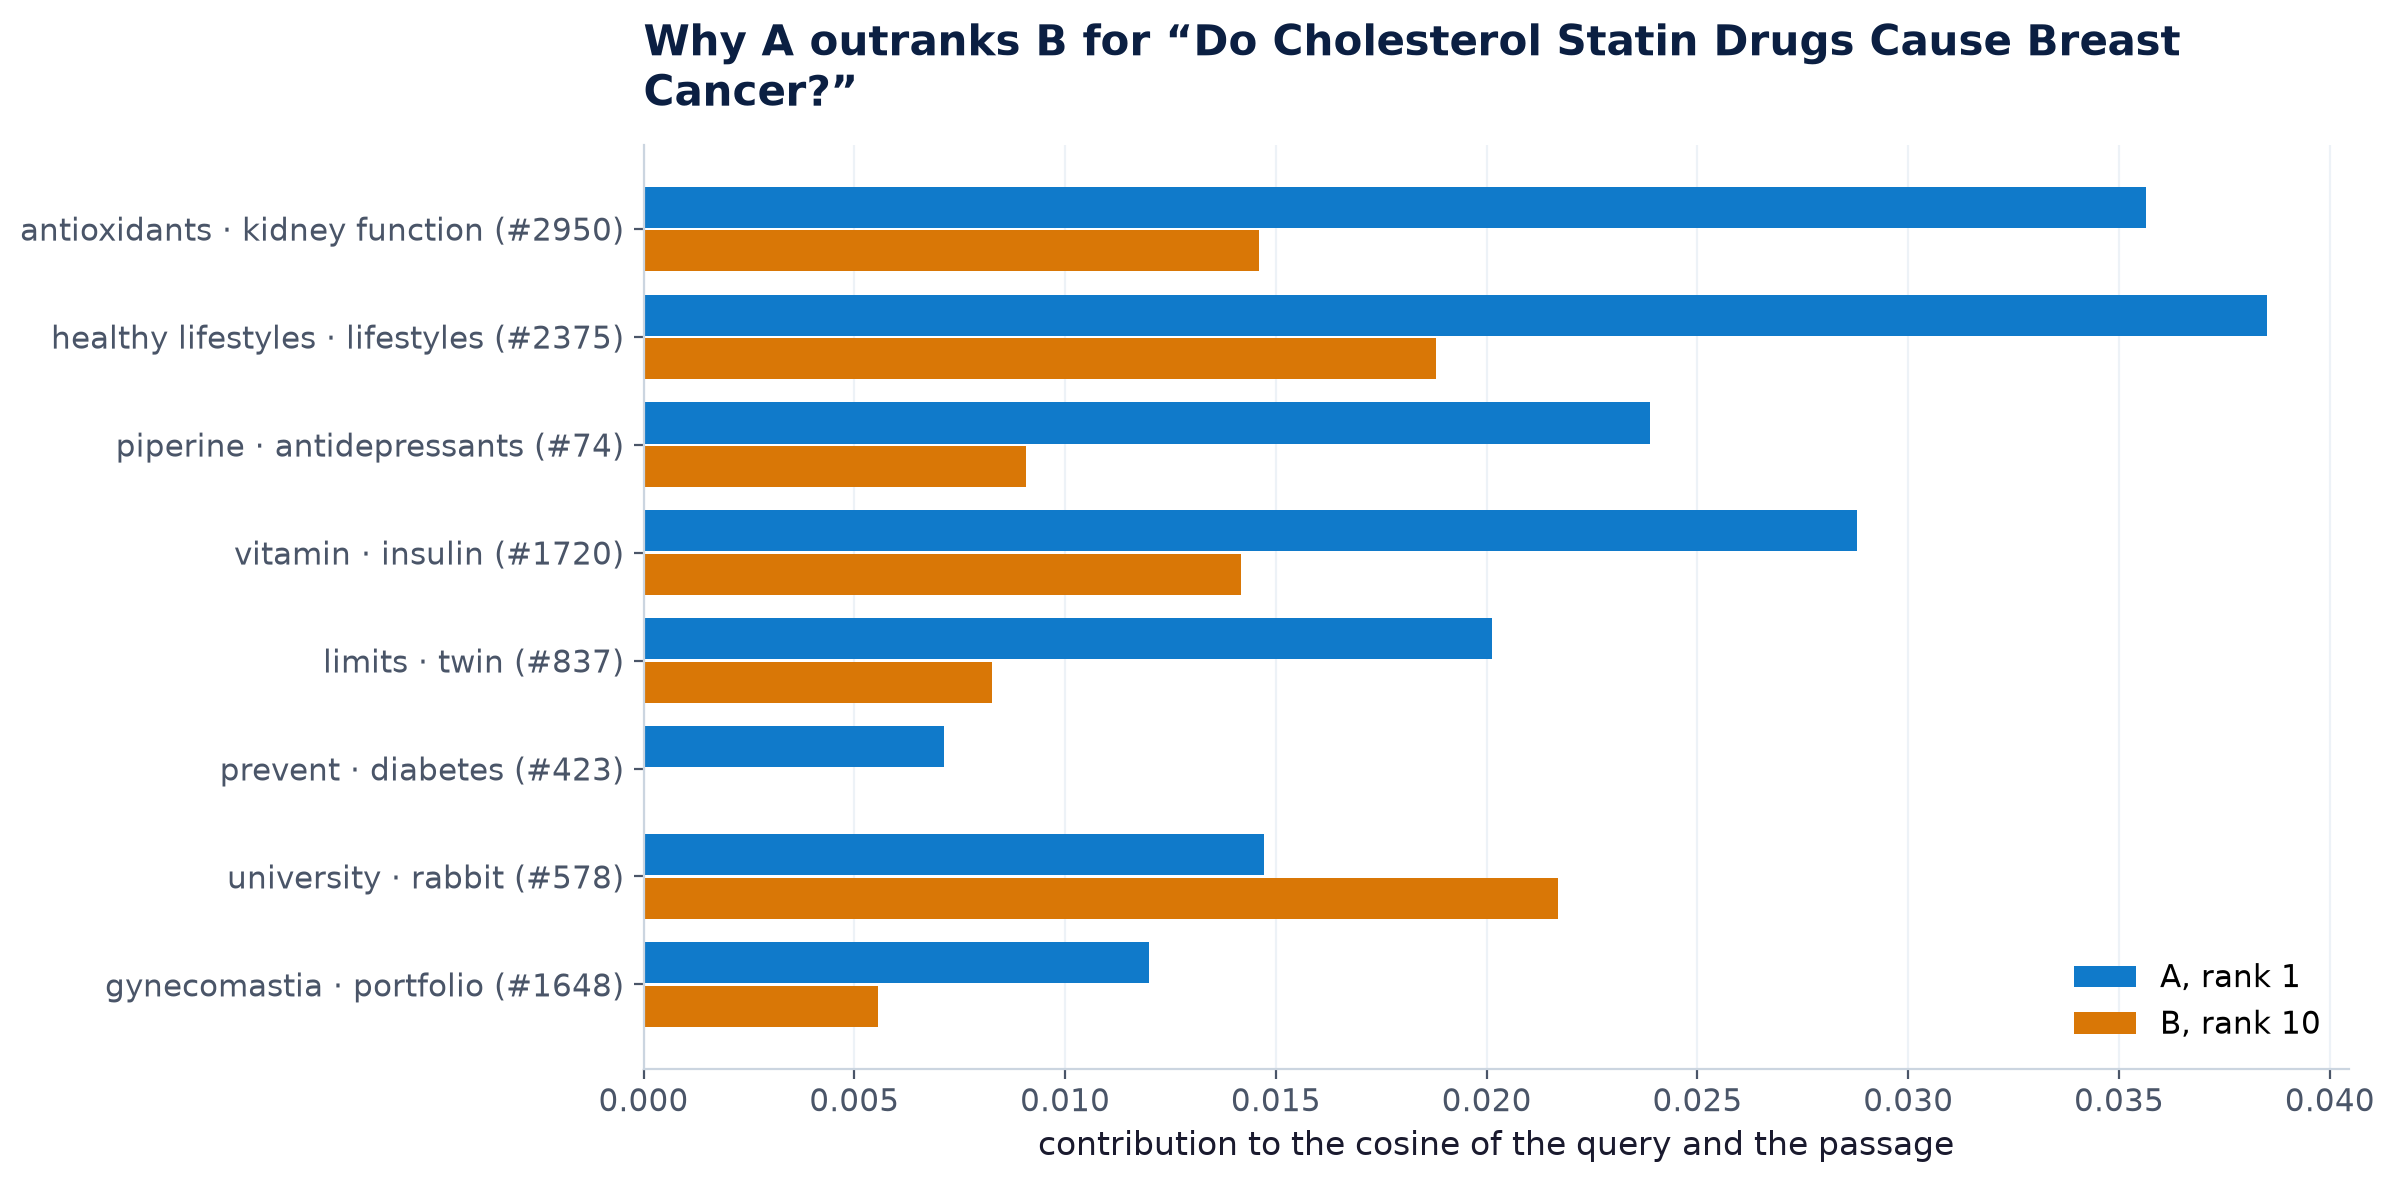

In [ ]:
query = dataset.queries["test"].text.iloc[0]
top, _ = search(sae, data.queries["test"][:1], data.corpus, top_k=10, device=device)
first, tenth = dataset.corpus.text.iloc[top[0, 0]], dataset.corpus.text.iloc[top[0, 9]]
explanation = interpreter.explain(query, first, tenth, n_features=8, cards=cards)
show_explanation(explanation, interpreter)

Features are named by their LLM topic when you ran MedGemma, else by their two strongest TF IDF terms on
NFCorpus. Those are rough names for a checkpoint trained on another corpus, roughest for the generic features
that fire on most documents.

## 7 🔍 Search with your own question

Type a question in the field and run the cell. It is embedded with the same encoder, encoded by the SAE and
matched against every abstract; the chips are the topic specific features it shares with each result.

In [ ]:
# @title Ask NFCorpus a question
question = "Does eating red meat increase the risk of colon cancer?"  # @param {type:"string"}

ask = search_engine(sae, embedder, data, interpreter, corpus_codes)
ask(question)

## 8 🏋️ Train your own DoctoSAE

The paper objective: reconstruct each embedding, and pull queries towards their relevant documents with an
InfoNCE loss on the sparse codes. `TrainingConfig()` holds the paper settings; 30 epochs instead of 100 keep this
demo to about a minute on a GPU.

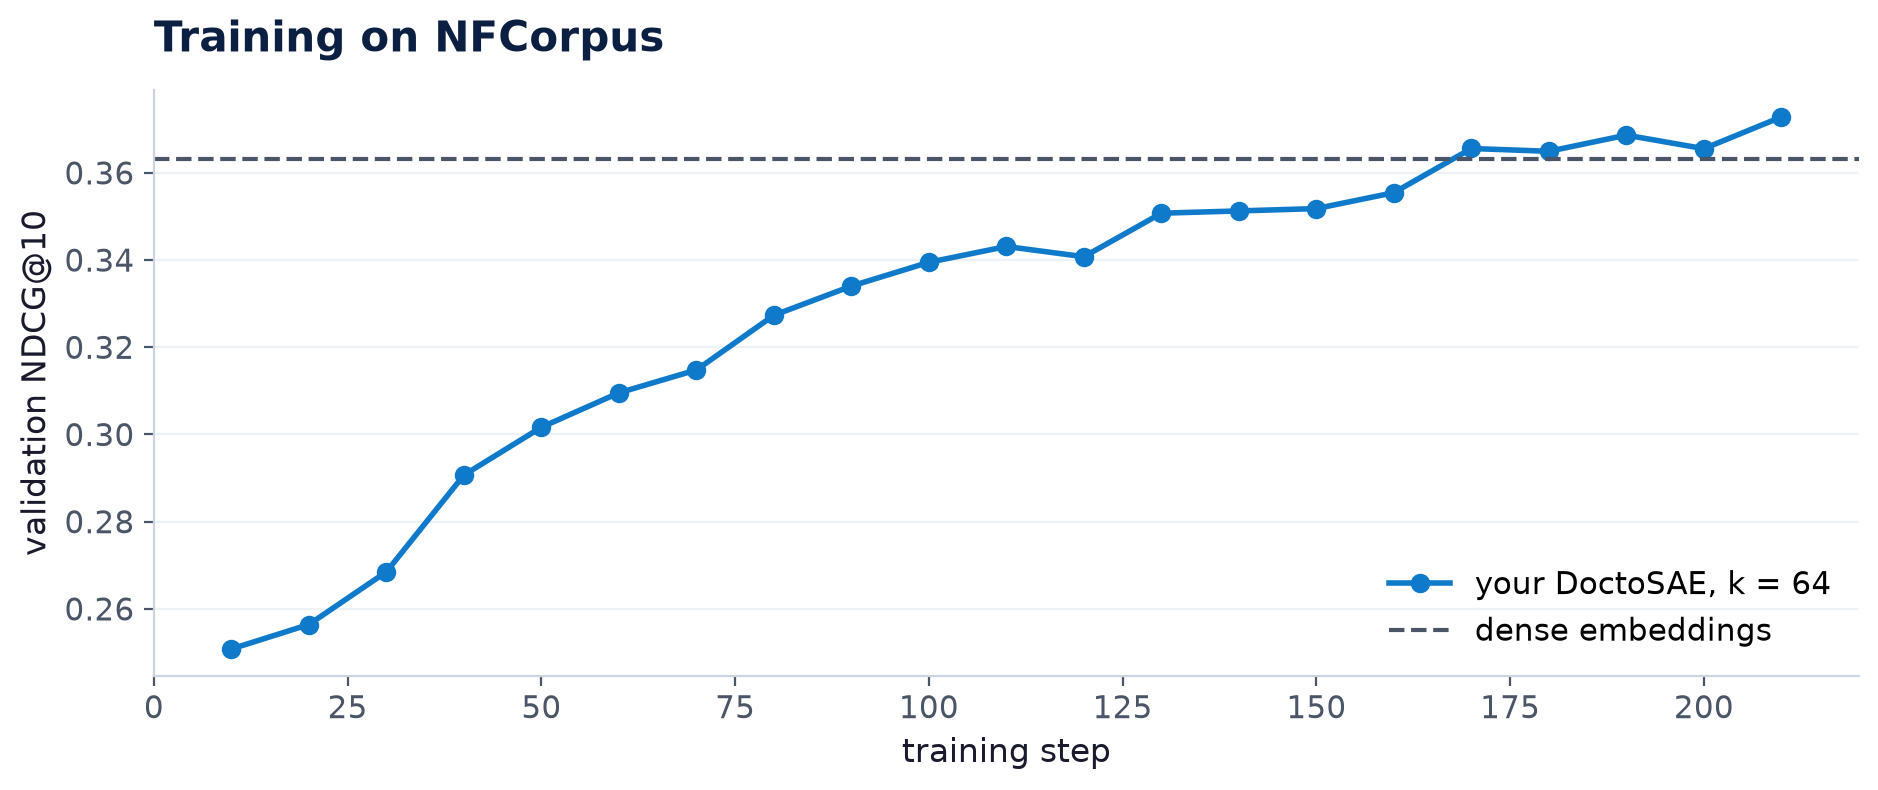

,ndcg@10,recall@100,mrr@10
dense BGE embeddings,0.382,0.364,0.574
"DoctoSAE, k = 256, trained on CURE",0.356,0.338,0.546
"DoctoSAE, k = 64, trained here on NFCorpus",0.391,0.418,0.558


In [ ]:
torch.manual_seed(42)
my_sae = DoctoSAE(d_in=data.dim, n_latents=3 * data.dim, k=64, embedder=data.embedder)
config = TrainingConfig(epochs=30, eval_every=10, device=device)
trainer = Trainer(my_sae, config, output_dir="runs/nfcorpus/sae").fit(data)

plot_training(trainer.history, dense=evaluate(None, data, split="val")["ndcg@10"])
scores["DoctoSAE, k = 64, trained here on NFCorpus"] = evaluate(trainer.best_model, data, split="test")
show_scores(scores)

> 📤 **Share it:** `trainer.best_model.push_to_hub("your-name/doctosae-nfcorpus-k64")` publishes the checkpoint
> on the Hub, private by default, and `load_pretrained(repo_id=...)` loads it back.

## 🚀 Where to go next

* 📄 **Paper:** [arXiv 2611.18179](https://arxiv.org/abs/2611.18179), ML4H 2026
* 📦 **Package:** `pip install doctosae`; the full API and the `doctosae` command line are in the [README](https://github.com/doctolib-lab/doctosae)
* 🤗 **Checkpoints:** BGE, MedEmbed and Gemini SAEs in the [DoctoSAE collection](https://huggingface.co/collections/doctolib-lab/doctosae)
* 🧪 **Reproduce the paper:** [`paper/`](https://github.com/doctolib-lab/doctosae/tree/main/paper) holds the exact code behind every table
* 🩺 **Annotation app:** the Streamlit app used with clinicians, in [`annotation_app/`](https://github.com/doctolib-lab/doctosae/tree/main/annotation_app)

### Cite

```bibtex
@misc{bouchacourt2026explanationstransferinterpretingmedical,
      title={Explanations that Transfer: Interpreting Medical Retrieval with Sparse AutoEncoders},
      author={Diane Bouchacourt and Gaëtan Brison},
      year={2026},
      eprint={2611.18179},
      archivePrefix={arXiv},
      primaryClass={cs.IR},
      url={https://arxiv.org/abs/2611.18179},
}
```

## 🎉 Congrats, you made it

If DoctoSAE helps your work, a ⭐ on [GitHub](https://github.com/doctolib-lab/doctosae) helps us a lot.